# Visualisasi Kreatif Performance & Scalability Testing — Tim 2

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

# Notebook diletakkan sejajar dengan folder evidence/.
EVIDENCE = Path.cwd() / "evidence"
OUT = EVIDENCE / "visualisasi"
OUT.mkdir(parents=True, exist_ok=True)

# Palet warna khusus visualisasi KPPL; konsisten tetapi tidak bergantung pada template PPT.
NAVY = "#102B3A"; TEAL = "#00A99B"; ORANGE = "#F18F45"
BLUE = "#5574BD"; MUTED = "#637787"; BG = "#F5F8FA"; RED = "#D85A65"
plt.rcParams.update({"figure.facecolor":"white", "axes.facecolor":BG,
                     "font.size":11, "axes.labelcolor":NAVY, "text.color":NAVY,
                     "axes.edgecolor":"#D8E3E8", "axes.spines.top":False,
                     "axes.spines.right":False, "grid.color":"#DCE7EC",
                     "savefig.facecolor":"white"})

def save_figure(name):
    plt.savefig(OUT / name, dpi=200, bbox_inches="tight")
    plt.show()
    print("Tersimpan:", OUT / name)

print("Folder sumber:", EVIDENCE)
print("Folder hasil:", OUT)

Folder sumber: d:\Tugas\KPPL_Kelompok2\evidence
Folder hasil: d:\Tugas\KPPL_Kelompok2\evidence\visualisasi


## A. Baca semua laporan k6 secara otomatis

Notebook akan mengabaikan JSON yang bukan ringkasan k6 dan melaporkan nama file yang diabaikan. Setiap file pengujian merupakan satu observasi; dua file 200 VU **tidak digabung**. Untuk grafik lintas beban, **semua JSON valid ditampilkan**, termasuk uji dengan durasi berbeda. Label grafik mencantumkan durasi estimasi dan nama file; perbandingan antar-durasi perlu ditafsirkan hati-hati.

In [2]:
if not EVIDENCE.is_dir():
    raise FileNotFoundError(f"Folder tidak ditemukan: {EVIDENCE}. Jalankan notebook dari folder proyek KPPL_Kelompok2.")

def get(obj, key, default=np.nan):
    return obj.get(key, default) if isinstance(obj, dict) else default

rows, ignored = [], []
for fp in sorted(EVIDENCE.glob("*.json")):
    try:
        raw = json.loads(fp.read_text(encoding="utf-8-sig"))
        m = raw.get("metrics", {})
        required = ["http_req_duration", "http_reqs", "http_req_failed", "checks", "vus_max"]
        if not all(k in m for k in required):
            ignored.append((fp.name, "tidak memiliki metrik ringkasan k6"))
            continue
        req = float(m["http_reqs"]["count"])
        rps = float(m["http_reqs"]["rate"])
        duration = req / rps if rps > 0 else np.nan
        vus = int(m["vus_max"].get("value", m["vus_max"].get("max")))
        checks = m["checks"]
        check_passes = int(checks.get("passes", 0))
        check_fails = int(checks.get("fails", 0))
        if (check_passes + check_fails) > 0:
            check_pct = 100 * check_passes / (check_passes + check_fails)
        else:
            check_pct = float(checks.get("value", np.nan)) * 100
        rows.append({
          "File": fp.name, "VU": vus, "Durasi estimasi (s)": duration,
          "Durasi kelompok (s)": int(round(duration / 10) * 10) if np.isfinite(duration) else -1,
          "Requests": int(req), "Iterations": int(get(m.get("iterations", {}), "count", -1)), "Req/s": rps,
          "Avg ms": float(m["http_req_duration"].get("avg", np.nan)),
          "Median ms": float(m["http_req_duration"].get("med", np.nan)),
          "p90 ms": float(m["http_req_duration"].get("p(90)", np.nan)),
          "p95 ms": float(m["http_req_duration"].get("p(95)", np.nan)),
          "Max ms": float(m["http_req_duration"].get("max", np.nan)),
          "Error %": 100 * float(m["http_req_failed"].get("value", np.nan)),
          "Checks %": check_pct,
          "Threshold p95 dilanggar": bool(any(m["http_req_duration"].get("thresholds", {}).values())),
          "Threshold error dilanggar": bool(any(m["http_req_failed"].get("thresholds", {}).values())),
          "Threshold checks dilanggar": bool(any(m["checks"].get("thresholds", {}).values())),
        })
    except (ValueError, KeyError, TypeError, OSError) as exc:
        ignored.append((fp.name, str(exc)))

if not rows:
    raise ValueError("Tidak ada JSON ringkasan k6 yang valid pada evidence/*.json")

all_df = pd.DataFrame(rows).sort_values(["Durasi kelompok (s)", "VU", "File"]).reset_index(drop=True)
# Semua file yang valid dipakai untuk grafik; JANGAN menyaring satu kelompok durasi.
main_df = all_df.sort_values(["VU", "Durasi estimasi (s)", "File"]).reset_index(drop=True)
main_df["Label"] = main_df.apply(
    lambda r: f"{int(r['VU'])} VU\n~{r['Durasi estimasi (s)']:.0f}s",
    axis=1
)
print(f"Ditemukan {len(all_df)} file pengujian; {len(ignored)} dilewati.")
print(f"Grafik memuat SEMUA {len(main_df)} file valid (durasi berbeda diberi label).")
# Peringatan jika jumlah iterasi tidak sesuai request; berguna untuk diagnosis file campuran.
if "Iterations" in main_df:
    suspicious = main_df[main_df["Requests"] != main_df["Iterations"]]
    if not suspicious.empty:
        print("PERHATIAN: request dan iterations berbeda di:", ", ".join(suspicious["File"]))
if ignored:
    print("File dilewati:")
    for filename, reason in ignored: print("-", filename, "—", reason)
display(all_df[["File","VU","Durasi estimasi (s)","Requests","Req/s","Avg ms","p95 ms","Error %","Checks %"]].round(2))
all_df.to_csv(OUT / "semua_hasil_k6.csv", index=False)
main_df.to_csv(OUT / "perbandingan_utama.csv", index=False)

Ditemukan 7 file pengujian; 0 dilewati.
Grafik memuat SEMUA 7 file valid (durasi berbeda diberi label).


,File,VU,Durasi estimasi (s),Requests,Req/s,Avg ms,p95 ms,Error %,Checks %
0,tc01.json,1,60.51,60,0.99,3.89,10.92,0.0,100.0
1,tc02.json,10,60.45,600,9.93,4.28,16.31,0.0,100.0
2,tc03.json,25,60.56,1500,24.77,4.95,17.16,0.0,100.0
3,tc04.json,50,60.67,3000,49.45,6.06,22.16,0.0,100.0
4,tc05.json,200,61.01,11892,194.92,11.07,52.43,0.0,100.0
5,tc06.json,250,61.04,14886,243.87,12.05,45.72,0.0,100.0
6,tc07.json,300,61.00,17835,292.40,11.58,40.38,0.0,100.0


**Catatan diagnostik:** Grafik ini sengaja menampilkan semua file ringkasan k6, tanpa menyaring berdasarkan durasi. Jika 250 VU belum muncul, cek tabel `all_df`: berarti file JSON tidak ditemukan di `evidence/*.json` atau isi file tidak valid. Untuk kesimpulan ilmiah, hindari membandingkan langsung run ~2 detik dengan run 60 detik seolah pengaturannya identik.


## 1 — Dashboard ringkasan: cerita pengujian dalam satu gambar

Bukan sekadar tabel: ringkasan metrik kunci, rentang beban, dan batas interpretasi.

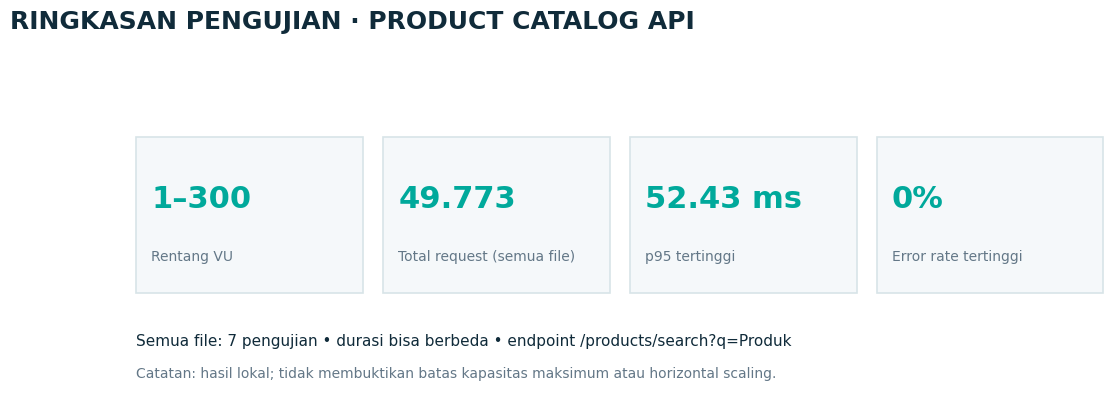

Tersimpan: d:\Tugas\KPPL_Kelompok2\evidence\visualisasi\01_dashboard_ringkasan.png


In [3]:
fig, ax = plt.subplots(figsize=(13, 4.6)); ax.axis("off")
fig.suptitle("RINGKASAN PENGUJIAN · PRODUCT CATALOG API", x=.055, y=.98, ha="left", fontsize=18, fontweight="bold")
items = [
 (f"{int(main_df['VU'].min())}–{int(main_df['VU'].max())}", "Rentang VU"),
 (f"{int(main_df['Requests'].sum()):,}".replace(",","."), "Total request (semua file)"),
 (f"{main_df['p95 ms'].max():.2f} ms", "p95 tertinggi"),
 (f"{main_df['Error %'].max():.0f}%", "Error rate tertinggi")]
for j,(value,label) in enumerate(items):
    x0=.035+j*.245
    ax.add_patch(plt.Rectangle((x0,.33),.225,.44,transform=ax.transAxes,facecolor=BG,edgecolor="#D8E4E8",linewidth=1.2))
    ax.text(x0+.015,.57,value,transform=ax.transAxes,fontsize=22,fontweight="bold",color=TEAL)
    ax.text(x0+.015,.42,label,transform=ax.transAxes,fontsize=10,color=MUTED)
ax.text(.035,.18, f"Semua file: {len(main_df)} pengujian • durasi bisa berbeda • endpoint /products/search?q=Produk", transform=ax.transAxes, fontsize=11)
ax.text(.035,.09,"Catatan: hasil lokal; tidak membuktikan batas kapasitas maksimum atau horizontal scaling.",transform=ax.transAxes,fontsize=10,color=MUTED)
save_figure("01_dashboard_ringkasan.png")

## 2 — Waktu respons: rata-rata, p95, dan puncak maksimum

Garis avg/p95 menyoroti kondisi tipikal; titik maksimum mengingatkan adanya request yang jauh lebih lambat. Maksimum sengaja dipisah pada panel kecil supaya skala tidak menutupi avg/p95.

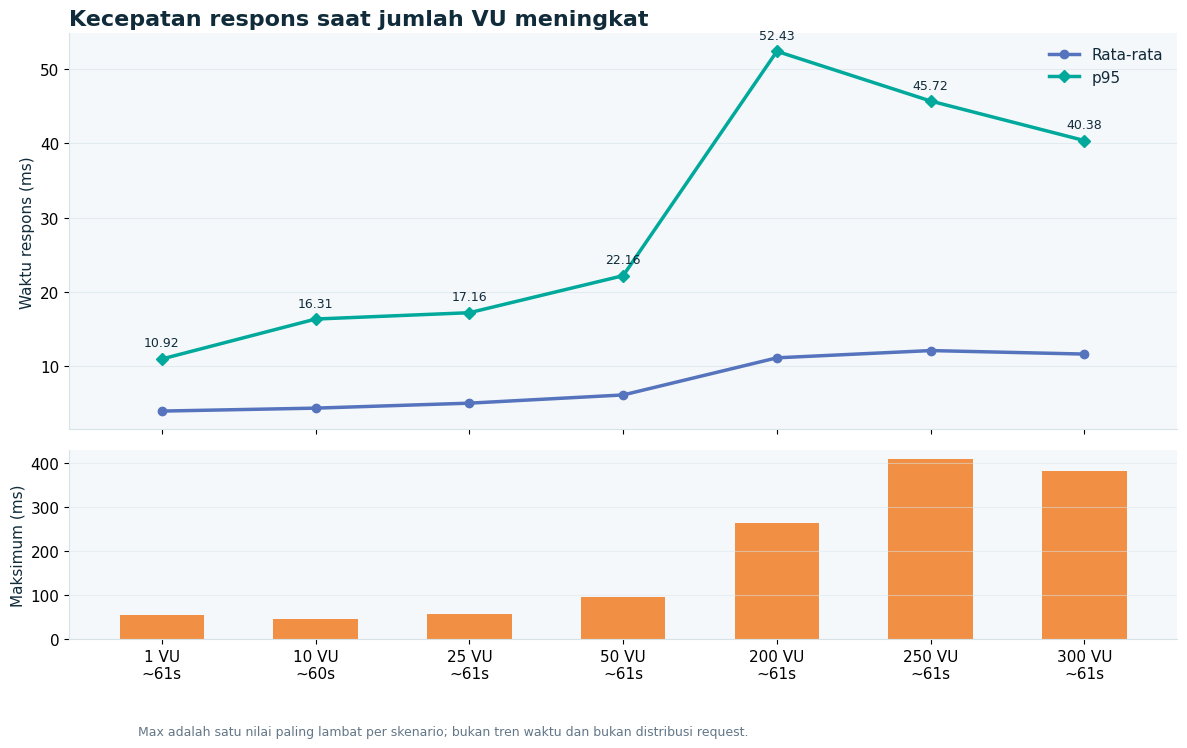

Tersimpan: d:\Tugas\KPPL_Kelompok2\evidence\visualisasi\02_profil_response_time.png


In [4]:
x=np.arange(len(main_df)); labels=main_df["Label"].tolist()
fig, axs=plt.subplots(2,1,figsize=(12,7.5),sharex=True,gridspec_kw={"height_ratios":[2.1,1]})
axs[0].plot(x,main_df["Avg ms"],"o-",lw=2.5,color=BLUE,label="Rata-rata")
axs[0].plot(x,main_df["p95 ms"],"D-",lw=2.5,color=TEAL,label="p95")
for i,v in enumerate(main_df["p95 ms"]): axs[0].annotate(f"{v:.2f}",(i,v),xytext=(0,9),textcoords="offset points",ha="center",fontsize=9)
axs[0].set_ylabel("Waktu respons (ms)"); axs[0].set_title("Kecepatan respons saat jumlah VU meningkat",loc="left",fontweight="bold",fontsize=16)
axs[0].grid(axis="y",alpha=.75);axs[0].legend(frameon=False)
axs[1].bar(x,main_df["Max ms"],width=.55,color=ORANGE)
axs[1].set_ylabel("Maksimum (ms)");axs[1].grid(axis="y",alpha=.5);axs[1].set_xticks(x,labels)
fig.text(.12,.01,"Max adalah satu nilai paling lambat per skenario; bukan tren waktu dan bukan distribusi request.",color=MUTED,fontsize=9)
plt.tight_layout(rect=(0,.06,1,1));save_figure("02_profil_response_time.png")

## 3 — Throughput aktual vs acuan ideal

**Acuan ideal** = throughput pada VU terkecil × perbandingan jumlah VU. Ini **bukan hasil k6**. Kesenjangan dari acuan membantu melihat apakah throughput mulai kehilangan proporsionalitas; `sleep(1)` turut memengaruhi hasil.

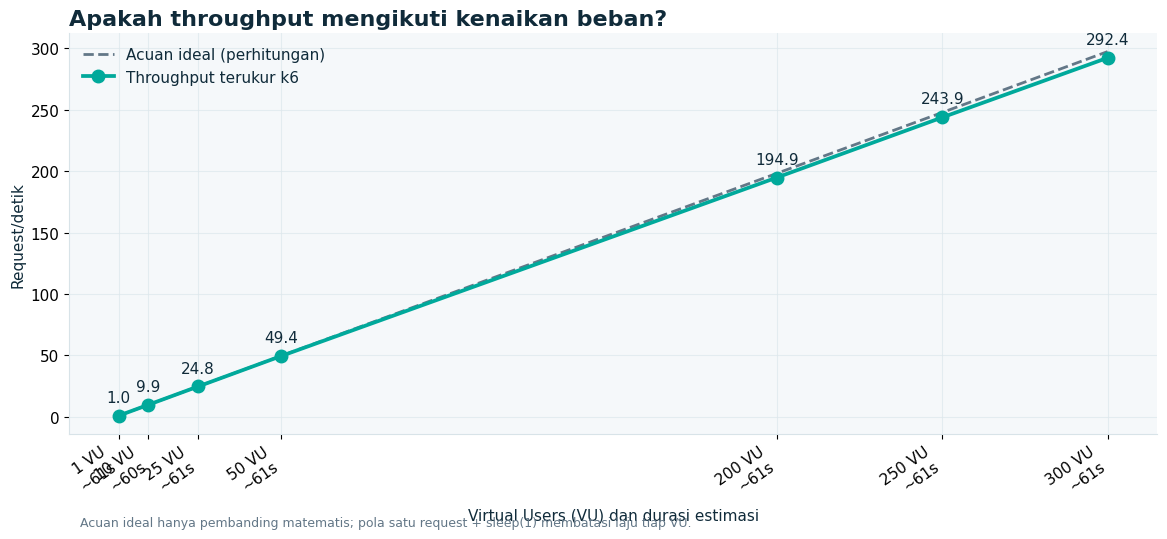

Tersimpan: d:\Tugas\KPPL_Kelompok2\evidence\visualisasi\03_throughput_vs_acuan.png


In [5]:
fig,ax=plt.subplots(figsize=(11.8,5.6)); vus=main_df["VU"].to_numpy(); rps=main_df["Req/s"].to_numpy()
reference=rps[0]*(vus/vus[0]); ax.plot(vus,reference,"--",color=MUTED,lw=2,label="Acuan ideal (perhitungan)")
ax.plot(vus,rps,"o-",color=TEAL,lw=2.7,ms=9,label="Throughput terukur k6")
for v,r in zip(vus,rps):ax.annotate(f"{r:.1f}",(v,r),xytext=(0,10),textcoords="offset points",ha="center")
ax.set_title("Apakah throughput mengikuti kenaikan beban?",loc="left",fontsize=16,fontweight="bold")
ax.set_xticks(vus,main_df["Label"].tolist(),rotation=35,ha="right");ax.set_xlabel("Virtual Users (VU) dan durasi estimasi");ax.set_ylabel("Request/detik");ax.grid(alpha=.7);ax.legend(frameon=False)
ax.text(.01,-.23,"Acuan ideal hanya pembanding matematis; pola satu request + sleep(1) membatasi laju tiap VU.",transform=ax.transAxes,color=MUTED,fontsize=9)
plt.tight_layout();save_figure("03_throughput_vs_acuan.png")

## 4 — Efisiensi laju request tiap VU

Melihat `req/s ÷ VU`. Nilai mendekati 1 request/detik/VU pada script ini **bukan** skor kapasitas atau efisiensi CPU; ini ukuran seberapa stabil laju iterasi VU di bawah jeda satu detik.

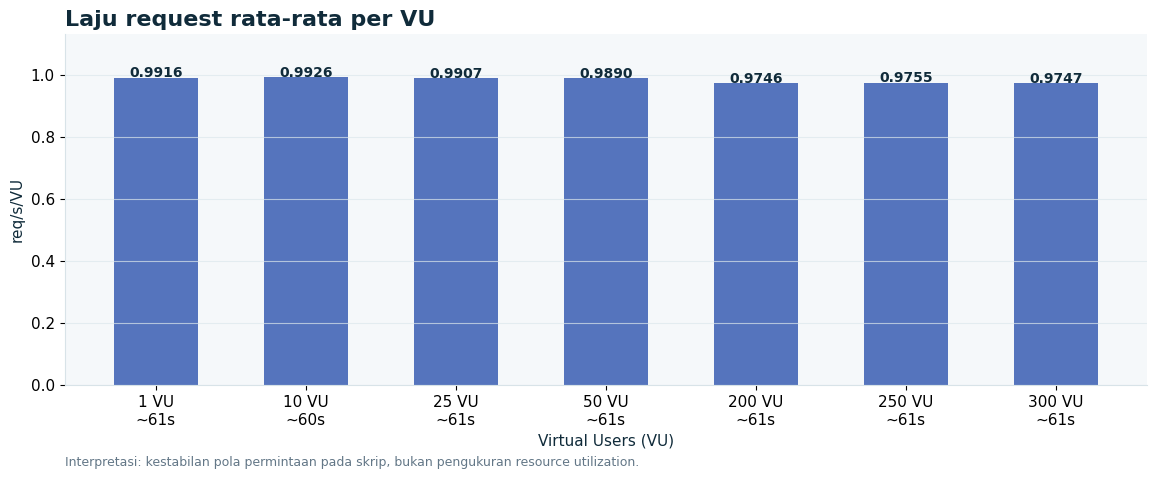

Tersimpan: d:\Tugas\KPPL_Kelompok2\evidence\visualisasi\04_laju_request_per_vu.png


In [6]:
fig,ax=plt.subplots(figsize=(11.7,5)); eff=main_df["Req/s"] / main_df["VU"]
ax.bar(main_df["Label"].tolist(),eff,color=BLUE,width=.56)
for j,z in enumerate(eff):ax.text(j,z+.001,f"{z:.4f}",ha="center",fontsize=10,fontweight="bold")
ax.set_ylim(0,max(1.08,eff.max()*1.14));ax.set_title("Laju request rata-rata per VU",loc="left",fontsize=16,fontweight="bold")
ax.set_ylabel("req/s/VU");ax.set_xlabel("Virtual Users (VU)");ax.grid(axis="y",alpha=.7)
ax.text(0,-.23,"Interpretasi: kestabilan pola permintaan pada skrip, bukan pengukuran resource utilization.",transform=ax.transAxes,color=MUTED,fontsize=9)
plt.tight_layout();save_figure("04_laju_request_per_vu.png")

## 5 — Seberapa jauh request terlambat dari kebanyakan request?

Rasio `maksimum / p95` memperlihatkan kemungkinan adanya ekor waktu respons lebih panjang. Ini **bukan** boxplot/distribusi lengkap: JSON agregat tidak memuat seluruh sampel request.

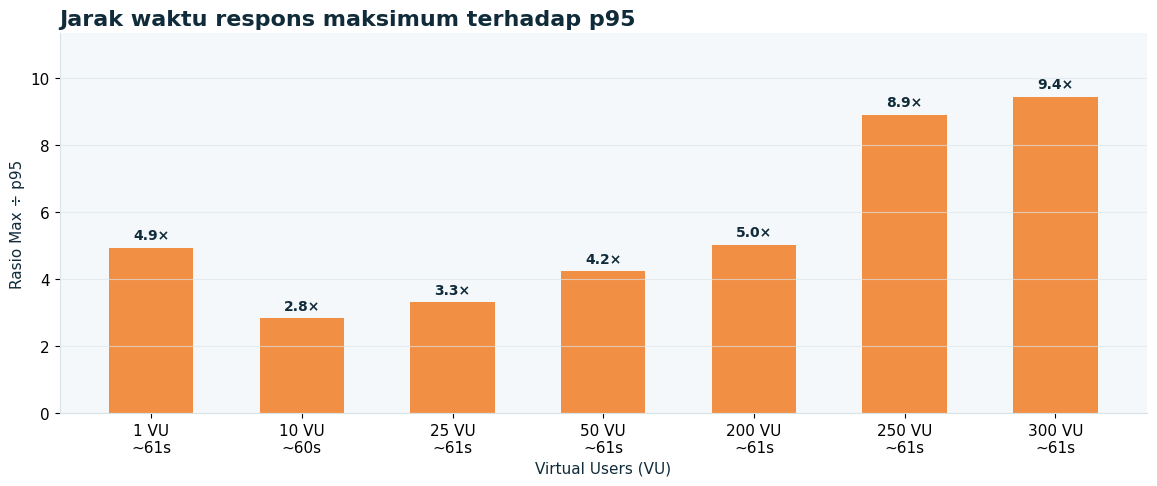

Tersimpan: d:\Tugas\KPPL_Kelompok2\evidence\visualisasi\05_rasio_max_ke_p95.png


In [7]:
fig,ax=plt.subplots(figsize=(11.7,5)); rat=main_df["Max ms"] / main_df["p95 ms"].replace(0,np.nan)
ax.bar(main_df["Label"].tolist(),rat,color=ORANGE,width=.56)
for j,z in enumerate(rat):
    if np.isfinite(z):ax.text(j,z+.25,f"{z:.1f}×",ha="center",fontsize=10,fontweight="bold")
ax.set_ylim(0,max(rat.max()*1.2,2));ax.set_title("Jarak waktu respons maksimum terhadap p95",loc="left",fontsize=16,fontweight="bold")
ax.set_ylabel("Rasio Max ÷ p95");ax.set_xlabel("Virtual Users (VU)");ax.grid(axis="y",alpha=.65)
plt.tight_layout();save_figure("05_rasio_max_ke_p95.png")

## 6 — Kualitas request dan status threshold

Menampilkan persentase *checks* dan *error rate* dalam satu grafik, serta status threshold asli dari file. Pada ekspor k6, `false` dalam `thresholds` berarti **tidak dilanggar**.

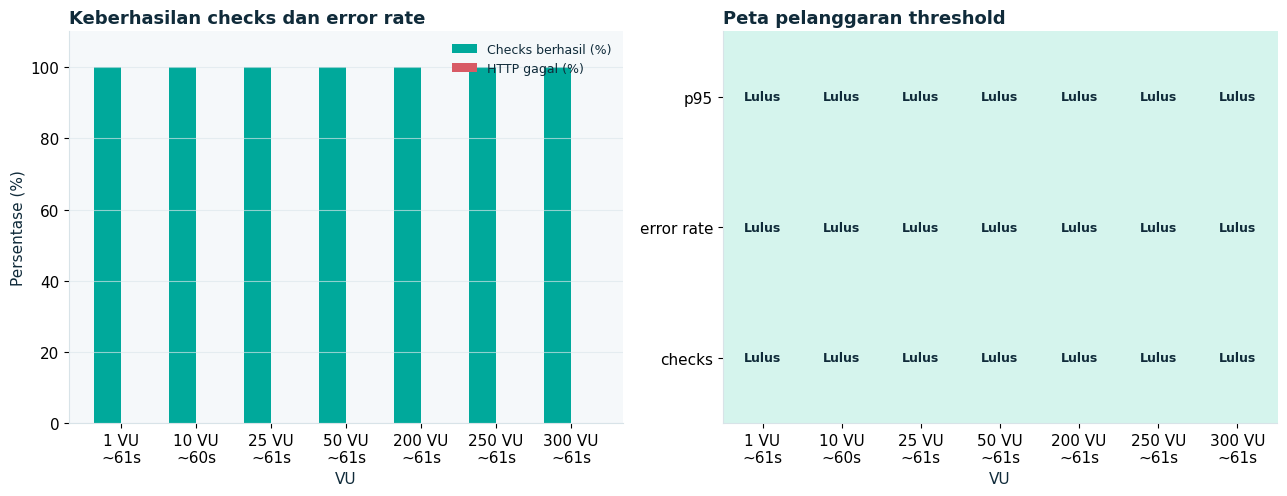

Tersimpan: d:\Tugas\KPPL_Kelompok2\evidence\visualisasi\06_kualitas_dan_threshold.png


In [8]:
fig,axs=plt.subplots(1,2,figsize=(13,5.1))
xx=np.arange(len(main_df));lbl=main_df["Label"].tolist()
axs[0].bar(xx-.18, main_df["Checks %"],width=.36,color=TEAL,label="Checks berhasil (%)")
axs[0].bar(xx+.18, main_df["Error %"],width=.36,color=RED,label="HTTP gagal (%)")
axs[0].set_xticks(xx,lbl);axs[0].set_ylim(0,110);axs[0].set_xlabel("VU");axs[0].set_ylabel("Persentase (%)")
axs[0].set_title("Keberhasilan checks dan error rate",loc="left",fontsize=13,fontweight="bold")
axs[0].legend(frameon=False,fontsize=9);axs[0].grid(axis="y",alpha=.65)
threshold_names=["p95","error rate","checks"]
columns=["Threshold p95 dilanggar","Threshold error dilanggar","Threshold checks dilanggar"]
statuses=np.array([[0 if not bool(row[c]) else 1 for c in columns] for _,row in main_df.iterrows()])
from matplotlib.colors import ListedColormap
axs[1].imshow(statuses.T,aspect="auto",vmin=0,vmax=1,cmap=ListedColormap(["#D5F4ED","#FFE0E1"]))
axs[1].set_xticks(xx,lbl);axs[1].set_yticks(range(3),threshold_names);axs[1].set_xlabel("VU")
axs[1].set_title("Peta pelanggaran threshold",loc="left",fontsize=13,fontweight="bold")
for i in range(3):
    for j in range(len(main_df)):
        axs[1].text(j,i,"Lulus" if statuses[j,i]==0 else "Gagal",ha="center",va="center",fontsize=9,fontweight="bold",color=NAVY)
plt.tight_layout();save_figure("06_kualitas_dan_threshold.png")

## 7 — Jika ada uji ulang pada VU sama, bandingkan hasilnya

Misalnya 200 VU selama 60 s vs 120 s. Perbandingan memakai **req/s, avg, p95**, bukan jumlah request mentah, karena durasi berbeda.

In [9]:
counts=all_df.groupby("VU")["File"].nunique()
repeat_vus=counts[counts>1].index.tolist()
if repeat_vus:
    focus=int(repeat_vus[-1]); sub=all_df[all_df["VU"]==focus].sort_values("Durasi estimasi (s)")
    labs=[f"{r['File']}\n~{r['Durasi kelompok (s)']}s" for _,r in sub.iterrows()]
    fig,axs=plt.subplots(1,2,figsize=(13.3,5))
    axs[0].bar(labs,sub["Req/s"],color=TEAL,width=.55)
    axs[0].set_title(f"Throughput pada {focus} VU",loc="left",fontweight="bold");axs[0].set_ylabel("req/s")
    for i,val in enumerate(sub["Req/s"]):axs[0].text(i,val+1,f"{val:.2f}",ha="center")
    ix=np.arange(len(sub));axs[1].bar(ix-.18,sub["Avg ms"],.36,label="Avg",color=BLUE)
    axs[1].bar(ix+.18,sub["p95 ms"],.36,label="p95",color=ORANGE)
    axs[1].set_xticks(ix,labs);axs[1].set_title("Waktu respons",loc="left",fontweight="bold");axs[1].set_ylabel("ms");axs[1].legend(frameon=False)
    for ax in axs:ax.grid(axis="y",alpha=.65)
    plt.tight_layout();save_figure("07_perbandingan_pengujian_ulang.png")
else:
    print("Tidak ada VU yang diuji pada lebih dari satu file. Grafik pengujian ulang dilewati.")

Tidak ada VU yang diuji pada lebih dari satu file. Grafik pengujian ulang dilewati.


## B. Ringkasan untuk laporan dan PPT

File gambar dan CSV tersimpan pada `evidence/visualisasi/`. Grafik **2, 3, dan 6** paling cocok untuk eksplorasi. Untuk presentasi utama, bandingkan hanya run dengan durasi dan pengaturan yang sama; grafik ini sengaja memperlihatkan semua eksperimen agar hasil 250/300/350 VU tidak hilang.

**Hal yang tidak boleh diklaim dari data ini:** kapasitas maksimum server, peningkatan horizontal scaling, dan grafik waktu respons per detik. Semua memerlukan skenario atau data tambahan.

In [10]:
summary = pd.DataFrame({
    "Indikator": ["Tingkat beban diuji", "p95 tertinggi", "Error rate tertinggi", "Throughput tertinggi", "Status semua threshold"],
    "Hasil": [f"{main_df['VU'].min()} hingga {main_df['VU'].max()} VU",
              f"{main_df['p95 ms'].max():.2f} ms",f"{main_df['Error %'].max():.2f}%",
              f"{main_df['Req/s'].max():.2f} req/s",
              "Lulus" if not main_df[["Threshold p95 dilanggar","Threshold error dilanggar","Threshold checks dilanggar"]].any().any() else "Ada yang dilanggar"]
})
display(summary)
summary.to_csv(OUT / "ringkasan_untuk_ppt.csv",index=False)
print("\nGambar keluaran:")
for f in sorted(OUT.glob("*.png")): print("•",f.name)

,Indikator,Hasil
0,Tingkat beban diuji,1 hingga 300 VU
1,p95 tertinggi,52.43 ms
2,Error rate tertinggi,0.00%
3,Throughput tertinggi,292.40 req/s
4,Status semua threshold,Lulus



Gambar keluaran:
• 01_dashboard_ringkasan.png
• 02_profil_response_time.png
• 03_throughput_vs_acuan.png
• 04_laju_request_per_vu.png
• 05_rasio_max_ke_p95.png
• 06_kualitas_dan_threshold.png
